<a href="https://colab.research.google.com/github/eveav2005-ai/Detective-de-senales/blob/main/Detective_de_Senales_Semanas1a3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Proyecto El Detective de Señales - Semanas 1, 2 y 3
# Aguilar Vargas Evelyn Adriana - 5402
# Fundamentos de Telecomunicaciones

# ===================== FASE 1: GENERACION Y PREPARACION DE DATOS =====================

# 1.1 Librerias
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.model_selection import train_test_split

In [ ]:
# 1.2 Parametros de la señal
# Con fs = 16 kHz se cumple Nyquist (fs >= 2*fmax), la frecuencia mas alta es de unos 3.5 kHz
fs = 16000      # frecuencia de muestreo (Hz)
fc = 2000       # frecuencia de la portadora (Hz)
Rs = 1000       # tasa de simbolos (baudios)
muestras_simbolo = fs // Rs          # 16 muestras por simbolo
num_simbolos = 16                    # simbolos por señal
N = muestras_simbolo * num_simbolos  # 256 muestras por señal

clases = ["ASK", "FSK", "PSK", "QAM"]

print("muestras por simbolo:", muestras_simbolo)
print("muestras por señal:", N)

muestras por simbolo: 16
muestras por señal: 256


In [ ]:
# 1.3 Funciones para generar las señales
# A cada señal se le da una fase inicial al azar porque el receptor no sabe en que fase llega la portadora

t = np.arange(muestras_simbolo) / fs   # tiempo de un simbolo

# ASK: bit 1 = se manda la portadora, bit 0 = amplitud cero
def ask(fase):
    bits = np.random.randint(0, 2, num_simbolos)
    s = []
    for k in range(num_simbolos):
        tk = t + k / Rs
        s.append(bits[k] * np.cos(2*np.pi*fc*tk + fase))
    return np.concatenate(s)

# FSK: bit 0 = 1500 Hz, bit 1 = 2500 Hz
def fsk(fase):
    bits = np.random.randint(0, 2, num_simbolos)
    s = []
    for k in range(num_simbolos):
        tk = t + k / Rs
        if bits[k] == 1:
            f = fc + 500
        else:
            f = fc - 500
        s.append(np.cos(2*np.pi*f*tk + fase))
    return np.concatenate(s)

# PSK (BPSK): bit 1 = fase 0°, bit 0 = fase 180°
def psk(fase):
    bits = np.random.randint(0, 2, num_simbolos)
    s = []
    for k in range(num_simbolos):
        tk = t + k / Rs
        if bits[k] == 1:
            s.append(np.cos(2*np.pi*fc*tk + fase))
        else:
            s.append(np.cos(2*np.pi*fc*tk + fase + np.pi))
    return np.concatenate(s)

# 16-QAM: cambia amplitud y fase, I y Q pueden valer -3, -1, 1 o 3
# son 4x4 = 16 combinaciones, o sea 4 bits por simbolo
def qam(fase):
    niveles = [-3, -1, 1, 3]
    s = []
    for k in range(num_simbolos):
        I = np.random.choice(niveles)
        Q = np.random.choice(niveles)
        tk = t + k / Rs
        s.append(I*np.cos(2*np.pi*fc*tk + fase) - Q*np.sin(2*np.pi*fc*tk + fase))
    return np.concatenate(s)

# normalizar para que todas las señales tengan potencia 1
def normalizar(x):
    return x / np.sqrt(np.mean(x**2))

generadores = [ask, fsk, psk, qam]

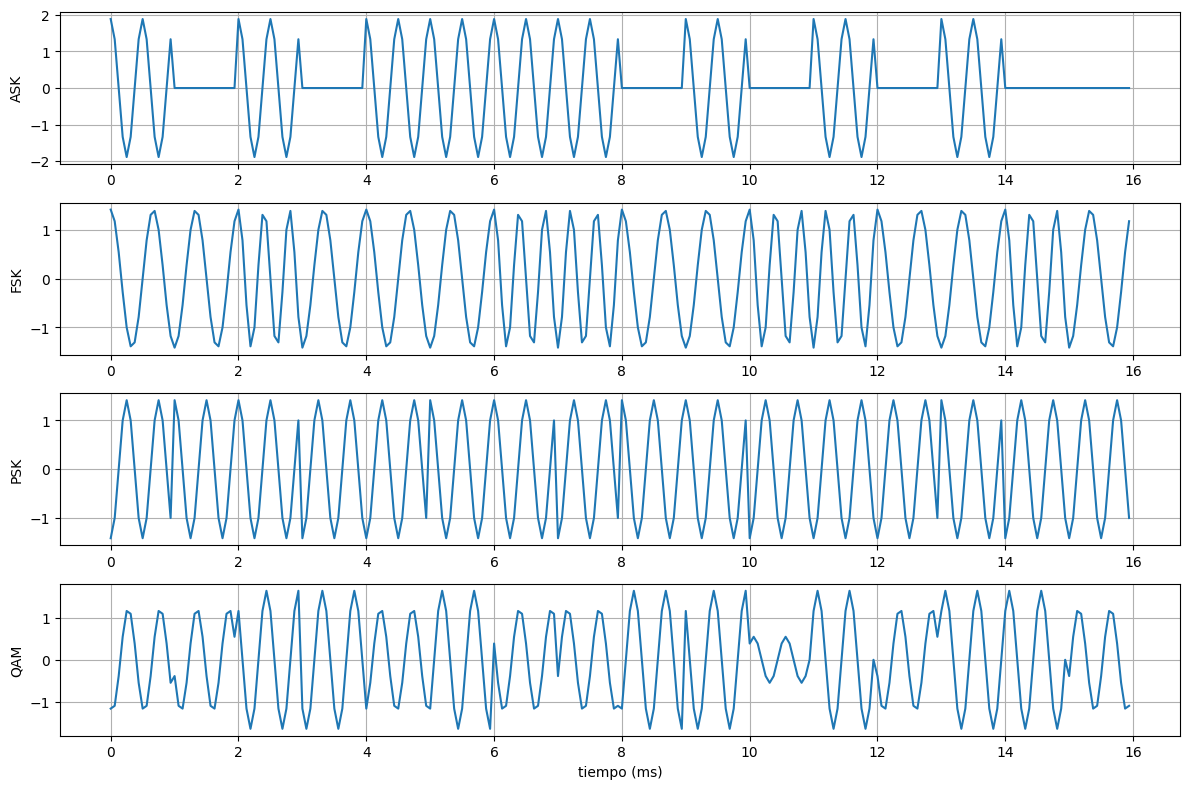

In [ ]:
# Grafica de un ejemplo de cada modulacion sin ruido
np.random.seed(7)
tiempo = np.arange(N) / fs * 1000   # en ms

plt.figure(figsize=(12, 8))
for i in range(4):
    plt.subplot(4, 1, i+1)
    plt.plot(tiempo, normalizar(generadores[i](0)))
    plt.ylabel(clases[i])
    plt.grid()
plt.xlabel("tiempo (ms)")
plt.tight_layout()
plt.show()

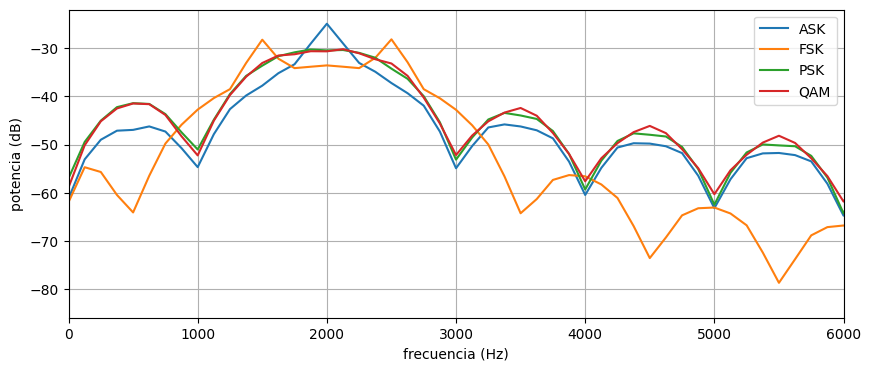

In [ ]:
# Espectro de cada modulacion (promedio de 30 señales)
# FSK debe tener dos picos (1.5 y 2.5 kHz) y las demas estar centradas en 2 kHz
plt.figure(figsize=(10, 4))
for i in range(4):
    P_total = 0
    for j in range(30):
        x = normalizar(generadores[i](np.random.uniform(0, 2*np.pi)))
        f, P = signal.welch(x, fs=fs, nperseg=128)
        P_total = P_total + P
    plt.plot(f, 10*np.log10(P_total/30), label=clases[i])
plt.xlabel("frecuencia (Hz)")
plt.ylabel("potencia (dB)")
plt.xlim(0, 6000)
plt.legend()
plt.grid()
plt.show()

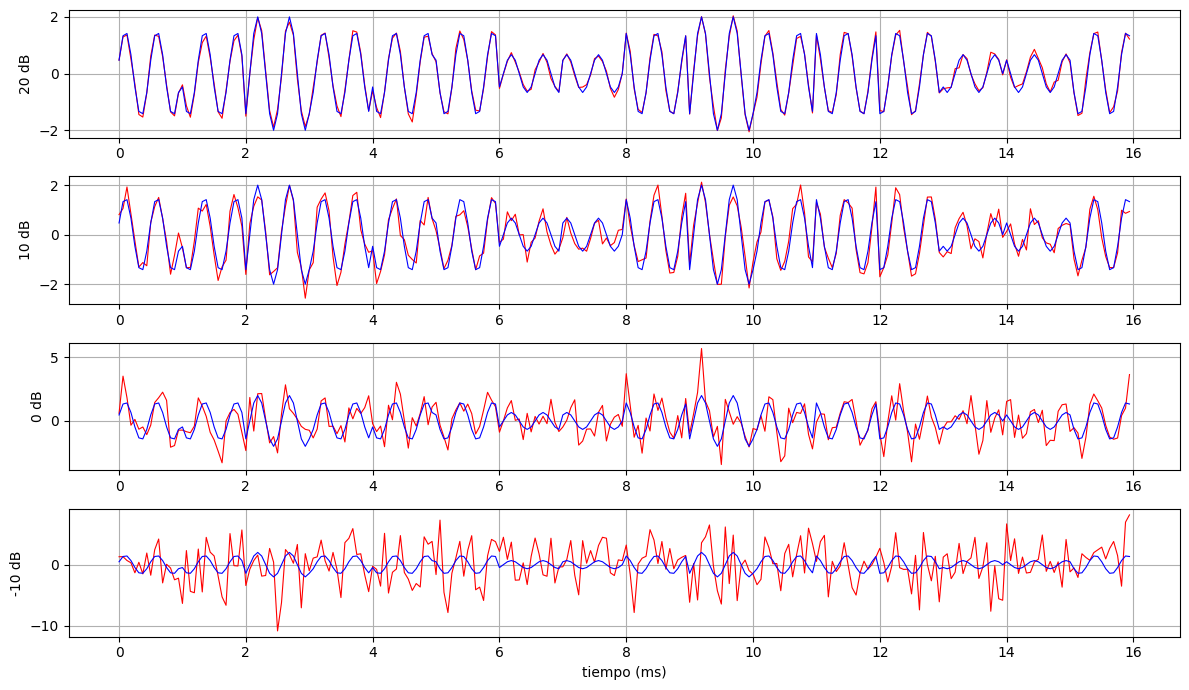

In [ ]:
# 1.5 Ruido AWGN
# la potencia del ruido se calcula con: P_ruido = P_señal / 10^(SNR/10)
def agregar_ruido(x, snr):
    p_senal = np.mean(x**2)
    p_ruido = p_senal / (10**(snr/10))
    ruido = np.random.normal(0, np.sqrt(p_ruido), len(x))
    return x + ruido

# misma señal QAM con diferentes niveles de ruido
# con 20 dB casi no se nota, con -10 dB la señal casi no se ve
np.random.seed(3)
x = normalizar(qam(0))
snrs_prueba = [20, 10, 0, -10]

plt.figure(figsize=(12, 7))
for i in range(4):
    plt.subplot(4, 1, i+1)
    plt.plot(tiempo, agregar_ruido(x, snrs_prueba[i]), "r", linewidth=0.8)
    plt.plot(tiempo, x, "b", linewidth=0.8)
    plt.ylabel(str(snrs_prueba[i]) + " dB")
    plt.grid()
plt.xlabel("tiempo (ms)")
plt.tight_layout()
plt.show()

In [ ]:
# 1.4 Generacion del dataset
# 7 niveles de SNR x 300 señales x 4 modulaciones = 8400 señales (2100 por modulacion)
# X = señales, y = etiqueta (0=ASK, 1=FSK, 2=PSK, 3=QAM), snr = nivel de ruido de cada señal
np.random.seed(42)
lista_snr = [-10, -5, 0, 5, 10, 15, 20]

X = []
y = []
snr = []
for etiqueta in range(4):
    for s in lista_snr:
        for n in range(300):
            fase = np.random.uniform(0, 2*np.pi)
            x = normalizar(generadores[etiqueta](fase))
            x = normalizar(agregar_ruido(x, s))
            X.append(x)
            y.append(etiqueta)
            snr.append(s)

X = np.array(X)
y = np.array(y)
snr = np.array(snr)

print("tamaño de X:", X.shape)
for i in range(4):
    print(clases[i], ":", np.sum(y == i), "señales")

tamaño de X: (8400, 256)
ASK : 2100 señales
FSK : 2100 señales
PSK : 2100 señales
QAM : 2100 señales


In [ ]:
# 1.6 Separacion: 80% entrenamiento y 20% prueba
# stratify=y para que haya la misma cantidad de cada modulacion en los dos grupos
X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X, y, snr, test_size=0.2, random_state=42, stratify=y)

print("entrenamiento:", X_train.shape[0])
print("prueba:", X_test.shape[0])

# guardar los datos para usarlos despues
np.savez("dataset.npz", X_train=X_train, X_test=X_test, y_train=y_train,
         y_test=y_test, snr_train=snr_train, snr_test=snr_test)

entrenamiento: 6720
prueba: 1680


In [ ]:
# ===================== FASE 2: DISEÑO Y ENTRENAMIENTO DEL MODELO =====================

# 2.1 Se usa una red convolucional 1D (1D-CNN) que recibe directamente la forma de onda.
# Los filtros de convolucion funcionan parecido a un filtro FIR: cada uno aprende a detectar
# un patron (cambio de fase, de frecuencia o de amplitud) en cualquier parte de la señal.
# La otra opcion seria convertir la señal en espectrograma y usar una CNN 2D.

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

# cargar los datos guardados (por si se abre el cuaderno otra vez)
datos = np.load("dataset.npz")
X_train = datos["X_train"]
X_test = datos["X_test"]
y_train = datos["y_train"]
y_test = datos["y_test"]
snr_train = datos["snr_train"]
snr_test = datos["snr_test"]

# Keras necesita la forma (muestras, canales), se agrega 1 canal
X_train = X_train.reshape(-1, N, 1)
X_test = X_test.reshape(-1, N, 1)

# etiquetas en formato one-hot, por ejemplo PSK = [0, 0, 1, 0]
y_train_oh = keras.utils.to_categorical(y_train, 4)
y_test_oh = keras.utils.to_categorical(y_test, 4)

print(X_train.shape, y_train_oh.shape)

(6720, 256, 1) (6720, 4)


In [ ]:
# 2.2 Diseño del modelo
modelo = keras.Sequential([
    layers.Input(shape=(N, 1)),                           # entrada de 256 muestras
    layers.Conv1D(32, kernel_size=7, activation="relu"),  # 1a capa convolucional
    layers.MaxPooling1D(2),                               # reduce a la mitad
    layers.Conv1D(64, kernel_size=5, activation="relu"),  # 2a capa convolucional
    layers.MaxPooling1D(2),
    layers.Flatten(),                                     # pasa todo a un vector
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),                                  # para evitar sobreajuste
    layers.Dense(4, activation="softmax")                 # 4 salidas, una por modulacion
])

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 250, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 125, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 121, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3840)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       245,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 256,644 (1002.52 KB)

 Trainable params: 256,644 (1002.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 2.3 Compilar el modelo
# adam como optimizador, categorical_crossentropy porque son varias clases, y accuracy como metrica
modelo.compile(optimizer="adam",
               loss="categorical_crossentropy",
               metrics=["accuracy"])

In [ ]:
# 2.4 Entrenamiento
# 30 epocas, lotes de 64, el 10% del entrenamiento se usa para validacion
# EarlyStopping: si la validacion no mejora en 6 epocas se detiene y se queda con los mejores pesos
parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

historial = modelo.fit(X_train, y_train_oh,
                       epochs=30,
                       batch_size=64,
                       validation_split=0.1,
                       callbacks=[parar])

Epoch 1/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 16s 89ms/step - accuracy: 0.5144 - loss: 1.0380 - val_accuracy: 0.7307 - val_loss: 0.6322
Epoch 2/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7505 - loss: 0.5632 - val_accuracy: 0.8036 - val_loss: 0.4635
Epoch 3/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8292 - loss: 0.4127 - val_accuracy: 0.8185 - val_loss: 0.3973
Epoch 4/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8638 - loss: 0.3384 - val_accuracy: 0.8482 - val_loss: 0.3503
Epoch 5/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8947 - loss: 0.2752 - val_accuracy: 0.8497 - val_loss: 0.3333
Epoch 6/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9148 - loss: 0.2250 - val_accuracy: 0.8423 - val_loss: 0.3723
Epoch 7/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9234 - loss: 0.1980 - val_accuracy: 0.8318 - val_loss: 0.3829
Epoch 8/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9299 - loss: 0.1847 - val_accuracy: 0.8259 - val_los

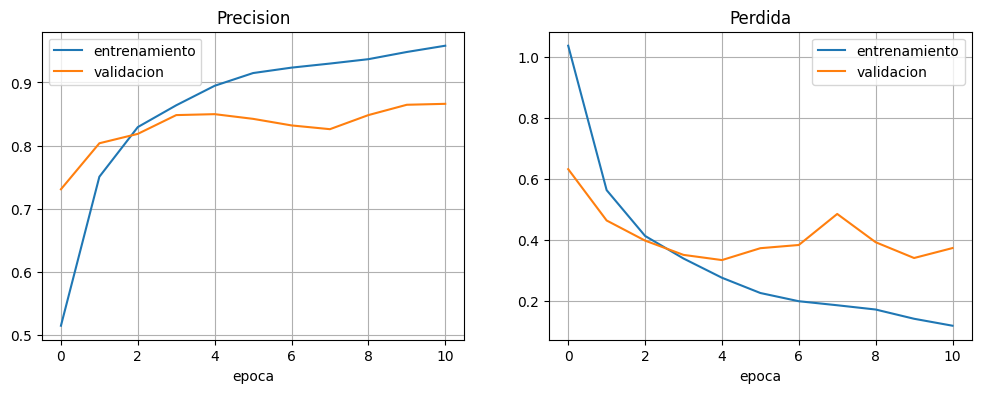

precision final de entrenamiento: 0.958
precision final de validacion: 0.866


In [ ]:
# Graficas de precision y perdida por epoca
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(historial.history["accuracy"], label="entrenamiento")
plt.plot(historial.history["val_accuracy"], label="validacion")
plt.title("Precision")
plt.xlabel("epoca")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(historial.history["loss"], label="entrenamiento")
plt.plot(historial.history["val_loss"], label="validacion")
plt.title("Perdida")
plt.xlabel("epoca")
plt.legend()
plt.grid()

plt.show()

print("precision final de entrenamiento:", round(historial.history["accuracy"][-1], 3))
print("precision final de validacion:", round(historial.history["val_accuracy"][-1], 3))

In [ ]:
# 2.5 Guardar el modelo para no volver a entrenarlo en la semana 3
modelo.save("detective_senales.keras")

# para cargarlo despues:
# modelo = keras.models.load_model("detective_senales.keras")

# para descargarlo a la computadora desde Colab:
# from google.colab import files
# files.download("detective_senales.keras")

53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step
precision en prueba: 0.863


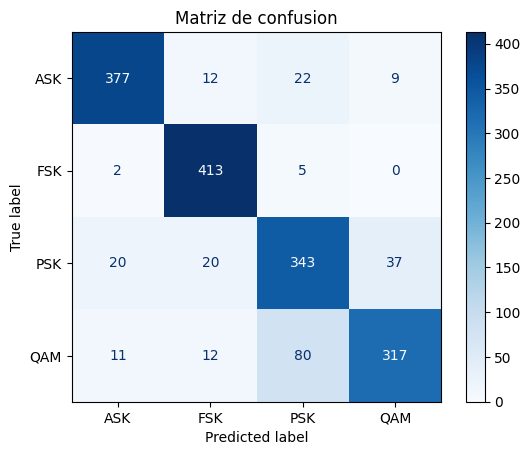

ASK confundida como PSK: 22
PSK confundida como ASK: 20


In [ ]:
# ===================== FASE 3: EVALUACION Y ROBUSTEZ =====================

# 3.1 Matriz de confusion
# se evalua el modelo con las señales de prueba (las que nunca vio al entrenar)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

prob = modelo.predict(X_test)
pred = np.argmax(prob, axis=1)   # la clase con mayor probabilidad

print("precision en prueba:", round(np.mean(pred == y_test), 3))

mc = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(mc, display_labels=clases).plot(cmap="Blues")
plt.title("Matriz de confusion")
plt.show()

# cuantas veces confundio ASK con PSK y al reves
print("ASK confundida como PSK:", mc[0, 2])
print("PSK confundida como ASK:", mc[2, 0])

In [ ]:
# 3.2 Prueba de estres con ruido
# se mide la precision separando las señales de prueba por nivel de ruido
bajo = (snr_test <= -5)                       # SNR bajo = mucho ruido
medio = (snr_test >= 0) & (snr_test <= 5)     # SNR medio
alto = (snr_test >= 10)                       # SNR alto = poco ruido

print("SNR bajo (-10 y -5 dB):", round(np.mean(pred[bajo] == y_test[bajo]), 3))
print("SNR medio (0 y 5 dB):", round(np.mean(pred[medio] == y_test[medio]), 3))
print("SNR alto (10 a 20 dB):", round(np.mean(pred[alto] == y_test[alto]), 3))

SNR bajo (-10 y -5 dB): 0.57
SNR medio (0 y 5 dB): 0.931
SNR alto (10 a 20 dB): 0.997


SNR -10 dB -> 0.454
SNR -5 dB -> 0.686
SNR 0 dB -> 0.885
SNR 5 dB -> 0.972
SNR 10 dB -> 0.991
SNR 15 dB -> 1.0
SNR 20 dB -> 1.0


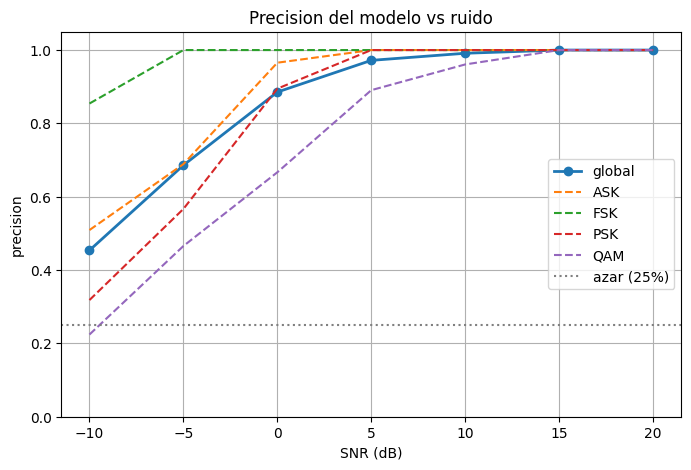

In [ ]:
# 3.3 Grafica de precision contra SNR
lista_snr = [-10, -5, 0, 5, 10, 15, 20]
precision_snr = []
for s in lista_snr:
    m = (snr_test == s)
    precision_snr.append(np.mean(pred[m] == y_test[m]))
    print("SNR", s, "dB ->", round(precision_snr[-1], 3))

plt.figure(figsize=(8, 5))
plt.plot(lista_snr, precision_snr, "o-", linewidth=2, label="global")
# tambien por cada modulacion
for k in range(4):
    p = []
    for s in lista_snr:
        m = (snr_test == s) & (y_test == k)
        p.append(np.mean(pred[m] == k))
    plt.plot(lista_snr, p, "--", label=clases[k])
plt.axhline(0.25, color="gray", linestyle=":", label="azar (25%)")
plt.xlabel("SNR (dB)")
plt.ylabel("precision")
plt.title("Precision del modelo vs ruido")
plt.ylim(0, 1.05)
plt.legend()
plt.grid()
plt.show()

In [ ]:
# 3.4 Analisis de errores: que modulacion fue la mas dificil
for k in range(4):
    acierto = mc[k, k] / np.sum(mc[k])
    print(clases[k], "acierto:", round(acierto, 3))

peor = np.argmin(np.diag(mc) / np.sum(mc, axis=1))
fila = mc[peor].copy()
fila[peor] = 0
print("la mas dificil fue", clases[peor], "y se confunde mas con", clases[np.argmax(fila)])

ASK acierto: 0.898
FSK acierto: 0.983
PSK acierto: 0.817
QAM acierto: 0.755
la mas dificil fue QAM y se confunde mas con PSK


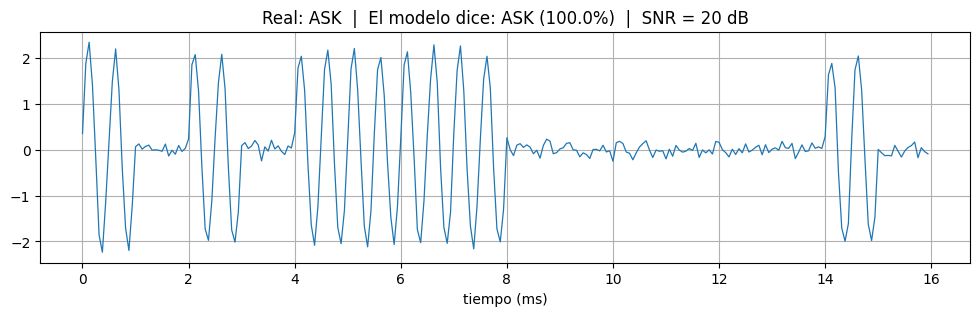

Probabilidades (%): ['ASK 100.0', 'FSK 0.0', 'PSK 0.0', 'QAM 0.0']


In [ ]:
# ===================== FASE 4: DEMOSTRACION =====================
# 4.2 Se genera una señal NUEVA al azar (modulacion y ruido al azar) y el modelo dice cual es
# se puede ejecutar esta celda varias veces, cada vez sale una señal diferente
np.random.seed()
k = np.random.randint(4)
snr_demo = int(np.random.choice([-5, 0, 5, 10, 20]))
x = normalizar(agregar_ruido(normalizar(generadores[k](np.random.uniform(0, 2*np.pi))), snr_demo))
p = modelo.predict(x.reshape(1, N, 1), verbose=0)[0]
plt.figure(figsize=(12, 3))
plt.plot(tiempo, x, linewidth=0.9)
plt.title("Real: " + clases[k] + "  |  El modelo dice: " + clases[np.argmax(p)] + " (" + str(round(p.max()*100, 1)) + "%)  |  SNR = " + str(snr_demo) + " dB")
plt.xlabel("tiempo (ms)")
plt.grid()
plt.show()
print("Probabilidades (%):", [clases[i] + " " + str(round(float(p[i])*100, 1)) for i in range(4)])